### **Maestría en Inteligencia Artificial Aplicada**

###**Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Problema de Clasificación con Datos Desbalanceados : Oil-Spill**

* **Nombre:** Lucía Alvarez Irigoyen

* **Matrícula:** A01840750

# **Introducción**

* La actividad se basa en los datos conocidos como "oil-spill" (derrame de petróleo).

* En la web puedes encontrar varias referencias a este mismo problema, pero en donde el archivo de datos no es exactamente igual. Por ello y para asegurar que el conjunto de datos con el que estaremos trabajando es el mismo para todos, dicho archivo lo encontrarás en Canvas.

* El archivo con los datos de esta actividad lo encuentras en Canvas con el nombre "oil-spill.csv".

* En la siguiente liga se encuentra el artículo original relacionado a dicha base de datos:

https://webdocs.cs.ualberta.ca/~holte/Publications/oilspill.pdf

* De dicho artículo sabemos que los datos incluyen 50 columnas y 937 registros. Las primeras 49 columnas son métricas obtenidas de imágenes satelitales del océano, en algunas de las cuales se tiene petróleo que fue derramado por alguna fuente desconocida. En el artículo se describe a detalle la manera en que se obtuvieron dichas columnas. Para la presente actividad es suficiente con saber que dichos valores numéricos son información valiosa que nos permiten entender lo qu hay en la imagen, en particular, el ayudar a distinguir si hay o no derramamiento de combustible en dicha imagen.

* La última columna llamada "target" puede tomar el valor de 1 (hay derrame en ese pedazo de la imagen) o 0 (no hay derrame en ese pedazo de la imagen).

* Así, por el momento es suficiente con que consideres que cada una de las primeras 49 columnas son variables de tipo numérico continua y la última es de valor binario, en este problema de clasificación.

* En un curso posterior de visión computacional dentro de la maestría podrás estudiar técnicas para extraer dicha información numérica de las imágenes, en caso de que este tema sea de tu interés.

* Para fines de esta actividad usaremos la librería llamada "imbalanced-learn", usada comunmente en problemas de clases desbalanceadas. En particular, usaremos el siguiente método que nos proporciona un reporte con los valores de varias métricas utilizadas comunmente en problemas de clases desbalanceadas:

https://imbalanced-learn.org/stable/references/generated/imblearn.metrics.classification_report_imbalanced.html

In [1]:
# Incluye a continuación todas librerías que consideres necesarias:

# Manejo y análisis de datos
import pandas as pd
import numpy as np

# Gráficas
import matplotlib.pyplot as plt
import seaborn as sns

# Separación de datos y validación cruzada
from sklearn.model_selection import (
    train_test_split,
    RepeatedStratifiedKFold,
    cross_val_score,
    GridSearchCV,
    cross_validate
)

# Preprocesamiento
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, StandardScaler

# Modelos de clasificación
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    make_scorer
)

# Métrica para datos desbalanceados
from imblearn.metrics import geometric_mean_score, classification_report_imbalanced

# Para ignorar advertencias, si es necesario
import warnings

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
DIR = "/content/drive/My Drive/Colab Notebooks/2do trimestre/Semana 4"
os.chdir(DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**NOTAS:**

* **Para fines de esta actividad, pre-procesaremos los datos de manera genérica para poder concentrarnos en los temas relacionados al curso.**

* **Siempre podrás regresar en el futuro y trabajar de mejor manera el pre-procesamiento de los datos.**

In [3]:
# Cargamos los datos del archivo de la actividad:
path ='oil_spill.csv'
df = pd.read_csv(path)

# Eliminamos las siguientes columnas:
#   - f_1 contiene información de secciones (batches) de las imágenes que no requerimos para esta actividad.
#   - f_23 tiene un solo valor constante.
df.drop("f_1", axis=1, inplace=True)
df.drop("f_23", axis=1, inplace=True)

# Despleguemos los primeros valores:
print('Dimensión del DataFrame',df.shape)
df.head(4).T


Dimensión del DataFrame (937, 48)


,0,1,2,3
f_2,2558.00,22325.00,115.00,1201.00
f_3,1506.09,79.11,1449.85,1562.53
f_4,456.63,841.03,608.43,295.65
f_5,90.00,180.00,88.00,66.00
f_6,6395000.00,55812500.00,287500.00,3002500.00
f_7,40.88,51.11,40.42,42.40
f_8,7.89,1.21,7.34,7.97
f_9,29780.00,61900.00,3340.00,18030.00
f_10,0.19,0.02,0.18,0.19
f_11,214.70,901.70,86.10,166.50


In [4]:
# Particionamos los datos de entrada (X) y de salida (y):
X,y = df.iloc[:,:-1], df.iloc[:,-1]

# Utilizamos las semillas indicadas para la reproducibilidad de los resultados de la actividad:
Xtv, Xtest, ytv, ytest = train_test_split(X, y, test_size=0.12, stratify=y, shuffle=True, random_state=1)
Xtrain, Xval, ytrain, yval = train_test_split(Xtv, ytv, test_size=0.2, shuffle=True, random_state=7)


# Veamos que tenemos un problema de clases bastante desbalanceadas.
# Para ello mostremos la distribución de los conjuntos de entrenamiento, validación y prueba.
# En realidad, solo deberíamos mostrar los valores del conjunto de entrenamiento
# para evitar el problema del filtrado de información (data leakage). Sin embargo,
# con fines meramente educativos, mostramos también la distribución de los conjuntos
# de validación (val) y de prueba (test), para darnos una idea de la complejidad del
# problema y del reto que tenemos para entrenar un buen modelo de clasificación.
# Es decir, tenemos una cantidad muy pequeña de datos de la clase positiva
# en el conjunto de validación y en el de prueba y aún así, deberemos
# hacer el esfuerzo para diseñar un buen modelo que distinga estos pocos datos.

print('\nPartición de los conjuntos de Entrenamiento, Validación y Prueba:')
print('+'*70)
tmp = 100 * (ytrain.sum() / len(ytrain))
print('Train:')
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytrain.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytrain)-ytrain.sum()), 100-tmp))

print('\nValidation:')
tmp = 100 * (yval.sum() / len(yval))
print('Conteo_clase_positiva= %d (%.2f%%)' % (yval.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(yval)-yval.sum()), 100-tmp))

print('\nTest:')
tmp = 100 * (ytest.sum() / len(ytest))
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytest.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytest)-ytest.sum()), 100-tmp))


Partición de los conjuntos de Entrenamiento, Validación y Prueba:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Train:
Conteo_clase_positiva= 28 (4.25%)
Conteo_clase_negativa= 631 (95.75%)

Validation:
Conteo_clase_positiva= 8 (4.85%)
Conteo_clase_negativa= 157 (95.15%)

Test:
Conteo_clase_positiva= 5 (4.42%)
Conteo_clase_negativa= 108 (95.58%)


# **Ejercicio-1**

### **Consideremos en primer instancia que los errores de falsos poitivos y falsos negativos son igualmente costosos. Y ya que tenemos un problema bastante desbalanceado, usaremos la media geométrica como métrica principal para buscar el mejor modelo. A partir de esta información, responde las siguientes preguntas:**

* ### **a) En el contexto de este problema del derrame de petróleo, ¿cómo justificas el no utilizar la métrica de la exactitud (accuracy), y sí utilizar la métrica G_mean?**

* ### **b) En el contexto del problema ¿qué significa un Falso Positivo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**

* ### **c) En el contexto del problema ¿qué significa un Falso Negativo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**





Respuestas Ejercicio-1:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 1a) La exactitud (Accuracy) mide la proporción total de predicciones correctas. Sin embargo, en este problema existe un fuerte desbalanceo entre las clases: la mayoría de los registros corresponden a zonas sin derrame (95%) y solamente una pequeña proporción representa derrames de petróleo (5%).
Por lo tanto, un modelo que prediga casi siempre que no hay derrame puede alcanzar una exactitud elevada sin ser útil para detectar los casos que realmente nos interesan.
La media geométrica (G-mean) permite evaluar simultáneamente la capacidad del modelo para identificar correctamente los registros de ambas clases.

G-mean es una métrica más apropiada cuando queremos equilibrar la detección de derrames y la identificación correcta de zonas sin derrame.

* 1b) Un falso positivo ocurre cuando el modelo predice que existe un derrame de petróleo, pero en realidad el área está limpia. Esto puede provocar el envío innecesario de helicópteros o embarcaciones, consumo de combustible, horas de trabajo del personal y gastos de inspección. También puede desviar recursos de otras zonas que sí necesitan atención.

* 1c) Un falso negativo ocurre cuando el modelo predice que no existe un derrame, aunque en realidad sí lo hay.
Este error es especialmente grave porque puede retrasar la detección y limpieza del combustible, aumentar el daño a los ecosistemas marinos, elevar los costos de recuperación y generar consecuencias legales y reputacionales para las autoridades responsables.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

* **Incluyamos a continuación una breve descripción numérica y gráfica del conjunto de entrenamiento. Es lo mínimo en cuanto a pre-procesamiento que haremos. Más adelante puedes regresar y realizar un mayor análisis.**

* **En dado caso, puedes incluir más celdas con análisis adicionales, si así lo deseas.**

In [5]:
Xtrain.describe().T

,count,mean,std,min,25%,50%,75%,max
f_2,659.0,350.377845,1.911459e+03,10.00,19.000,63.00,134.000,28526.00
f_3,659.0,692.040516,6.013521e+02,1.92,83.905,646.26,1229.325,1789.13
f_4,659.0,853.822398,5.259526e+02,1.00,435.500,719.81,1238.040,2724.57
f_5,659.0,85.613050,4.564260e+01,0.00,54.000,74.00,120.500,180.00
f_6,659.0,831366.966616,4.158159e+06,71718.00,125000.000,185000.00,337500.000,71315000.00
f_7,659.0,43.517132,1.287405e+01,21.24,33.760,40.35,53.090,82.64
f_8,659.0,9.244294,3.590490e+00,1.21,6.935,8.33,11.045,23.47
f_9,659.0,4094.624431,8.960913e+03,704.00,1332.000,2100.00,3445.000,160740.00
f_10,659.0,0.221730,8.687786e-02,0.02,0.170,0.21,0.260,0.67
f_11,659.0,110.794537,6.187135e+01,41.00,84.400,100.10,116.300,901.70


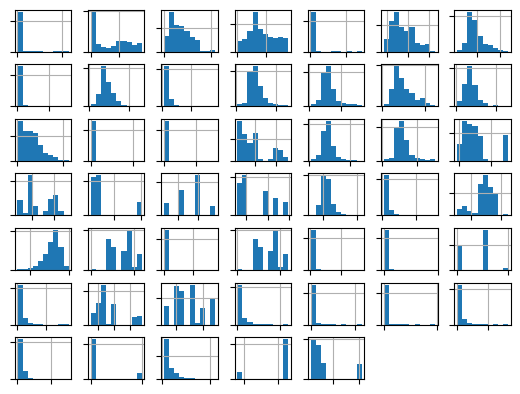

In [6]:
# Histogramas:
ax = Xtrain.hist()
# Quitemos toda la información del gráfico para visualizarlos de manera sencilla:
for axis in ax.flatten():
  axis.set_title('')
  axis.set_xticklabels([])
  axis.set_yticklabels([])
plt.show()



In [7]:
Xtrain.info()

<class 'pandas.core.frame.DataFrame'>
Index: 659 entries, 433 to 625
Data columns (total 47 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f_2     659 non-null    int64  
 1   f_3     659 non-null    float64
 2   f_4     659 non-null    float64
 3   f_5     659 non-null    int64  
 4   f_6     659 non-null    float64
 5   f_7     659 non-null    float64
 6   f_8     659 non-null    float64
 7   f_9     659 non-null    float64
 8   f_10    659 non-null    float64
 9   f_11    659 non-null    float64
 10  f_12    659 non-null    float64
 11  f_13    659 non-null    float64
 12  f_14    659 non-null    float64
 13  f_15    659 non-null    float64
 14  f_16    659 non-null    float64
 15  f_17    659 non-null    float64
 16  f_18    659 non-null    float64
 17  f_19    659 non-null    float64
 18  f_20    659 non-null    float64
 19  f_21    659 non-null    float64
 20  f_22    659 non-null    float64
 21  f_24    659 non-null    float64
 22  f_25 

**En resumen:**

* De lo anterior observamos que:
  * Todos los valores ya son numéricos, positivos, negativos o cero.
  * No hay datos perdidios.
  * La diferencia de escala entre todos los factores es muy diversa y la distribución de las variables también es muy variada.

* **Como una primera aproximación transformaremos todos los factores con la Yeo-Johnson para corregir un poco el sesgo de las distribuciones que suele afectar en general a los modelos como la regresión logística y luego los escalaremos para ayudar a que todos los factores estén en iguales condiciones de mostrar su importancia.**

# **Ejercicio-2**

### **En relación a la transformación Yeo-Johnson, investiga:**

* ### **a) ¿En qué consiste dicha transformación?**

* ### **b) ¿Cuál es su diferencia con la transformación Box-Cox?**


Respuestas Ejercicio-2:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 2a) Yeo-Johnson es una transformación matemática que busca reducir la asimetría de la distribución de una variable y hacerla más cercana a una distribución simétrica. Utiliza un parámetro que se estima a partir de los datos y permite aplicar distintas transformaciones según el valor de dicho parámetro.
Esta transformación puede ayudar a algunos modelos, como la regresión logística, a trabajar mejor con variables que presentan distribuciones muy sesgadas.
* 2b) La principal diferencia es el tipo de valores que aceptan:
- Yeo-Johnson: admite valores positivos, negativos y cero.
- Box-Cox: requiere valores estrictamente positivos.
Ambas transformaciones buscan reducir la asimetría de los datos mediante una transformación de potencia. Para este ejercicio, Yeo-Johnson resulta conveniente porque no requiere que todas las variables sean positivas.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [8]:
# Transformaciones numéricas evitando el filtrado de información:

from sklearn.preprocessing import MinMaxScaler

numericas_pipeline = Pipeline(steps = [('impMediana', SimpleImputer(strategy='mean')),
                                       ('yeo-johnson', PowerTransformer(method='yeo-johnson')),
                                       ('std_transformer', StandardScaler()),
                                       ])

numericas_pipeline_nombres = Xtrain.columns

columnasTransformer = ColumnTransformer(transformers = [('num', numericas_pipeline, numericas_pipeline_nombres)],
                                        remainder='passthrough')


# **Ejercicio-3**

### **En este ejercicio deberás obtener el valor de umbral del modelo base (baseline) con el conjunto de entrenamiento, que nos ayude a determinar si un modelo está subentrenado.**

* ### **a) Encuentra la estrategia (strategy) del DummyClassifier más adecuada. Además, selecciona el número de divisiones (n_splits) de RepeatedStratifiedKFold que consideres sea el más adecuado para particionar en los conjuntos de entrenamiento y validación al aplicar validación cruzada con el modelo DummyClassifier. Prueba varios valores y observa el resultado de la media y desviación estándar antes de hacer tu mejor selección. Responde a continuación cómo llegaste a decidirte por valor que seleccionaste.**

* ### **b) Con base a tu mejor decisión para "strategy" y "n_splits", ¿cuál es el valor que se usará para determinar si un modelo está subentrenado, al usar la métrica G_mean?**

* ### **c) Si utilizáramos la métrica de la exactitud (accuracy) en este problema del derrame del petróleo, ¿cuál sería el valor de umbral del modelo base a superar? Incluye además la matriz de confusión de este modelo ingenuo con la métrica de la exactitud.**

Respuestas Ejercicio-3:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 3a) Probé las estrategias most_frequent, prior, stratified y uniform de DummyClassifier, utilizando validación cruzada estratificada repetida. Comparé la media y la desviación estándar de G-mean.

Las estrategias `most_frequent` y `prior` obtienen un G-mean igual a cero. La estrategia `stratified` tiene un G-mean bajo cercano a 0. Finalmente, la estrategia `uniform` tiene un G-mean de 0.5 aproximadamente, escogiendo esta estrategia con `n_splits = 7`, ya que es el valor que proporciona un mayor G-mean de 0.551 y una desviación estándar de 0.067.

* 3b) El umbral de referencia es la media de G-mean del DummyClassifier seleccionado. Un modelo que obtenga un desempeño inferior a 0.505 no demuestra una mejora respecto al clasificador aleatorio seleccionado.

* 3c) El clasificador ingenuo que siempre predice la clase mayoritaria obtiene una exactitud teórica de: 631 / 659 ~= 95.75%. En el conjunto de entrenamiento, que contiene 631 registros negativos y 28 positivos, la matriz de confusión de un clasificador que siempre predice cero es:

\begin{bmatrix}631&0\\28&0\end{bmatrix}


Las filas representan las clases reales y las columnas las predicciones. El modelo clasifica correctamente todos los registros negativos (VP = 631 y VN = 28), pero no detecta ninguno de los derrames.



### +++++++++++ Termina sección para agregar texto ++++++++++++++

NOTA: Recuerda revisar la documentación correspondiente de sklearn para la selección adecuada de los argumentos:

* DummyClassifier:

https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

* RepeatedStratifiedKFold:

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html

In [9]:
# Definamos una variable con la métrica G-mean a utilizar en los modelos:

mi_metrica = make_scorer(geometric_mean_score)


In [10]:
# Utilicemos la función DummyClassifier de sklearn con la métrica G-mean para
# obtener el desempeño del modelo base (baseline).

# Usa esta celda para probar diferentes valores de "strategy" y "n_splits".
# Con base a los resultados observados selecciona tus mejores opciones y
# responde a las preguntas de los incisos anteriores del Ejercicio-3.

strategies = ['most_frequent', 'prior', 'stratified', 'uniform']
splits = [3, 5, 7, 10]

for st in strategies:
    print('Modelo: ',st)
    for n_sp in splits:

        cv = RepeatedStratifiedKFold(n_splits=n_sp,n_repeats=3,random_state=7)

        modelo_dummy = DummyClassifier(strategy=st,random_state=7)

        pipeline_dummy = Pipeline(steps=[('ct', columnasTransformer),
                                          ('Dummy', modelo_dummy)
                                        ]
                                  )

        scores = cross_val_score(pipeline_dummy,Xtrain,np.ravel(ytrain),
                                  scoring=mi_metrica,cv=cv,n_jobs=-1
                                )

        print(f"n_splits = {n_sp}, Media: {np.mean(scores):.3f}, Desviación: {np.std(scores):.3f}")


# ----------------- Incluye a continuación tus mejores opciones -----------

mi_estrategia = 'uniform'

mi_nsplits = 3


# ----------------- Fin para realizar ajustes -----------------------------



# No modifiques las semillas.
cv = RepeatedStratifiedKFold(n_splits=mi_nsplits, n_repeats=3, random_state=7)  # Validación Cruzada Estratificada.
modeloD = DummyClassifier(strategy=mi_estrategia, random_state=7)
pipelineD = Pipeline(steps=[('ct',columnasTransformer),('Dummy',modeloD)])
scores = cross_val_score(pipelineD, Xtrain, ytrain, scoring=mi_metrica, cv=cv, n_jobs=-1)  # Cuidamos el filtrado de información.

print('Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.')
print('Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:')
print('+'*90)
print(scores)


print('\nObtenemos el valor promedio y desviación estandar (std) de dichos resultados:')
print('+'*80)
print('Promedio de los desempeños con la G-mean[Media Geométrica]=%.3f, std=(%.3f)' % (np.mean(scores), np.std(scores)))


Modelo:  most_frequent
n_splits = 3, Media: 0.000, Desviación: 0.000
n_splits = 5, Media: 0.000, Desviación: 0.000
n_splits = 7, Media: 0.000, Desviación: 0.000
n_splits = 10, Media: 0.000, Desviación: 0.000
Modelo:  prior
n_splits = 3, Media: 0.000, Desviación: 0.000
n_splits = 5, Media: 0.000, Desviación: 0.000
n_splits = 7, Media: 0.000, Desviación: 0.000
n_splits = 10, Media: 0.000, Desviación: 0.000
Modelo:  stratified
n_splits = 3, Media: 0.071, Desviación: 0.133
n_splits = 5, Media: 0.054, Desviación: 0.138
n_splits = 7, Media: 0.000, Desviación: 0.000
n_splits = 10, Media: 0.000, Desviación: 0.000
Modelo:  uniform
n_splits = 3, Media: 0.551, Desviación: 0.067
n_splits = 5, Media: 0.508, Desviación: 0.137
n_splits = 7, Media: 0.489, Desviación: 0.081
n_splits = 10, Media: 0.493, Desviación: 0.163
Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.
Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:
++++++++++++++++++

# **Ejercicio-4**

* ### **Ya que tenemos las referencias de los modelos base (baseline) o ingenuo (naive) para las métricas de exactitud (accuracy) y G-mean. Ejecuta a continuación la siguiente celda. Observa que estaremos ejecutando los modelos con el mínimo de ajuste de los valores predeterminados de los hiperparámetros. Esto con el objetivo de tener un punto de partida sobre qué tan alejados estamos de obtener buenos modelos. Sirve también como ejemplo para mostrar cómo se  desempeñan los modelos cuando se ejecutan con sus valores predeterminados, que en muchas ocasiones son los resultados que muestran algunos LLM (modelos grandes de lenguaje). Esto nos muestra que no porque no tengamos errores de ejecución o compilación, no significa que ya alcanzamos el objetivo buscado.**

* ### **Observa que estamos usando los conjuntos Xtv y ytv para entrenar los modelos ya que estamos utilizando validación cruzada y además, mostramos al inicio que tenemos muy pocos datos de la clase positiva minoritaria en el conjunto de validación.**

Resultados de Validación:
LR
Exactitud: >> 0.947 (0.015)
G-mean: >> 0.654 (0.119)

LASSO
Exactitud: >> 0.960 (0.009)
G-mean: >> 0.501 (0.158)

RIDGE
Exactitud: >> 0.959 (0.008)
G-mean: >> 0.541 (0.113)

EN
Exactitud: >> 0.960 (0.007)
G-mean: >> 0.540 (0.109)

kNN
Exactitud: >> 0.956 (0.006)
G-mean: >> 0.174 (0.187)



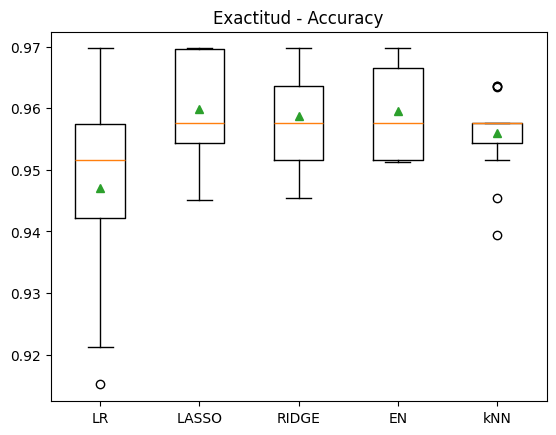

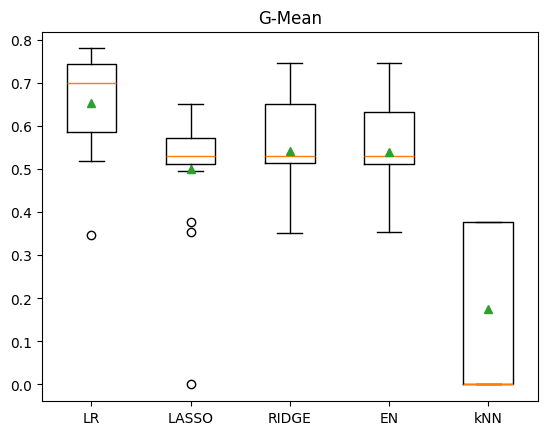

In [11]:
# Código-1:

# Ejecuta esta celda sin modificaciones.

# Estamos ejecutando los modelos con el mínimo de ajustes para usar sus valores predetermiandos
# y mostrando los desempeños con las métricas de exactitud (accuracy) y G-mean.

# Definimos primeramente los modelos a entrenar y evaluar:

def mis_modelos1():
  modelos, nombres = list(), list()

  modelos.append(LogisticRegression(penalty=None, # Este valor del argumento define el modelo sin regularización.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LR')


  modelos.append(LogisticRegression(penalty='l1',  # modelo Lasso o de métrica L1.
                                    solver='liblinear',
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LASSO')


  modelos.append(LogisticRegression(penalty='l2',   # modelo Ridge o de métrica L2.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('RIDGE')

  modelos.append(LogisticRegression(penalty='elasticnet',  # modelo Elastic-Net o de métrica L1-L2.
                                    l1_ratio=0.5,
                                    solver='saga',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('EN')

  modelos.append(KNeighborsClassifier(n_neighbors=5))
  nombres.append('kNN')

  return modelos, nombres

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++


modelos, nombres = mis_modelos1()
resultados1, resultados2 = list(), list()
print('Resultados de Validación:')

for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])
  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
  scores = cross_validate(pipeline,
                          Xtv,
                          np.ravel(ytv),
                          scoring={'exactitud':'accuracy', 'm_geo':mi_metrica},
                          cv=cv1)

  resultados1.append(scores['test_exactitud'])
  resultados2.append(scores['test_m_geo'])

  print(nombres[i])
  print('Exactitud: >> %.3f (%.3f)' % (np.nanmean(scores['test_exactitud']), np.nanstd(scores['test_exactitud'])))
  print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores['test_m_geo']), np.nanstd(scores['test_m_geo'])))
  print()

plt.boxplot(resultados1, tick_labels=nombres,  showmeans=True)
plt.title("Exactitud - Accuracy")
plt.show()

plt.boxplot(resultados2, tick_labels=nombres,  showmeans=True)
plt.title("G-Mean")
plt.show()




### **Habiendo ejecutado la celda anterior sin ajustar hiperparámetros, responde lo siguiente:**

### **4a) ¿Cuáles modelos están subentrenados con respecto a la métrica de la exactitud (accuracy)?**

### **4b) ¿Cuáles modelos están subentrenados con respecto a la métrica de la media geométrica (G-mean)?**


### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 4a) Considerando que el umbral de la exactitud es aproximadamente 95.75%, el modelo LR sin regularización y el modelo kNN están subentrenados con respecto a la exactitud, ya que su exactitud es de 0.947 y 0.956 respectivamente.

* 4b) Considerando que el umbral de G-mean es 0.551, los modelos Lasso (0.501), Ridge (0.541), En (.540) y kNN (0.174) están subentrenados con respecto a la media geométrica.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-5**

* ### **Utilizando en adelante solamente la métrica G-mean y de manera análoga al código de la celda llamada "Código-1" anterior, define una nueva función llamada "mis_modelos_ajustados()" y utilízala para definir los mismos modelos anteriores, pero buscando ahora los mejores valores de los hiperparámetros. Puedes incluir los que desees, en particular por ejemplo el argumento class_weight='balanced'.**

* ### **La salida no deberá mostrar errores o advertencias (warnings).**

* ### **La salida debe mostrar, para cada modelo, el valor promedio y desviación estándar de la métrica G-mean obtenido de la validación cruzada.**

* ### **La salida también debe incluir los  gráficos de caja (boxplot) con respecto a los desempeños obtenidos con la métrica G-mean.**


* ### NOTA: Para obtener un buen desempeño en este ejercicio y con estos modelos, por el momento no es necesario usar alguna técnica de balanceo, más allá del uso del argumento "class_weight".

Resultados de los modelos ajustados con la métrica G-mean
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
LR
Mejores parámetros: {'m__class_weight': 'balanced', 'm__solver': 'saga'}
G-mean promedio: 0.812
Desviación estándar: 0.081

LASSO
Mejores parámetros: {'m__C': 0.1, 'm__class_weight': 'balanced', 'm__solver': 'liblinear'}
G-mean promedio: 0.837
Desviación estándar: 0.052

RIDGE
Mejores parámetros: {'m__C': 0.01, 'm__class_weight': 'balanced', 'm__solver': 'liblinear'}
G-mean promedio: 0.828
Desviación estándar: 0.047

EN
Mejores parámetros: {'m__C': 0.01, 'm__class_weight': 'balanced', 'm__l1_ratio': 0.25}
G-mean promedio: 0.842
Desviación estándar: 0.058

kNN
Mejores parámetros: {'m__n_neighbors': 3, 'm__weights': 'uniform'}
G-mean promedio: 0.199
Desviación estándar: 0.186



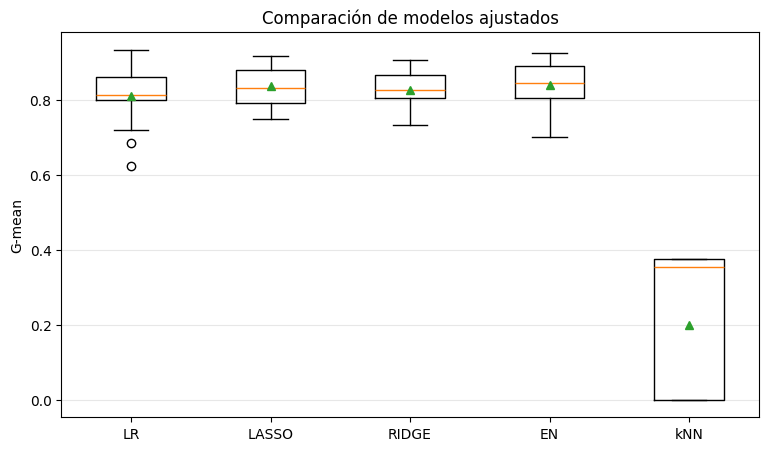

In [12]:
# 5)



print('Resultados de los modelos ajustados con la métrica G-mean')
print('+'*80)

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++
# NOTA: puedes agregar todas las celdas que consideres adecuado.

mi_metrica = make_scorer(geometric_mean_score)

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=7
)

def mis_modelos_ajustados():
    modelos = {
        'LR': (
            LogisticRegression(
                penalty=None, max_iter=2000,
                random_state=1
            ),
            {'m__class_weight': ['balanced'],
             'm__solver':['lbfgs','newton-cholesky','sag','saga']}
        ),
        'LASSO': (
            LogisticRegression(
                penalty='l1', max_iter=2000, random_state=1
            ),
            {'m__C': [0.01, 0.1, 1, 10],
             'm__solver':['liblinear','saga'],
             'm__class_weight': ['balanced']}
        ),
        'RIDGE': (
            LogisticRegression(
                penalty='l2', max_iter=2000,
                random_state=1
            ),
            {'m__C': [0.01, 0.1, 1, 10],
             'm__solver':['lbfgs','newton-cholesky','sag','saga','liblinear'],
             'm__class_weight': ['balanced']}
        ),
        'EN': (
            LogisticRegression(
                penalty='elasticnet', solver='saga', max_iter=5000,
                random_state=1
            ),
            {'m__C': [0.01, 0.1, 1, 10],
             'm__l1_ratio': [0.25, 0.5, 0.75],
             'm__class_weight': ['balanced']}
        ),
        'kNN': (
            KNeighborsClassifier(),
            {'m__n_neighbors': [3, 5, 7, 9, 11],
             'm__weights': ['uniform', 'distance']}
        )
    }

    return modelos

resultados = {}
resultados_gmean = []

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    for nombre, (modelo, parametros) in (
        mis_modelos_ajustados().items()
    ):
        pipe = Pipeline([
            ('ct', columnasTransformer),
            ('m', modelo)
        ])

        busqueda = GridSearchCV(
            pipe,
            parametros,
            scoring=mi_metrica,
            cv=cv,
            n_jobs=-1,
            error_score='raise'
        )

        busqueda.fit(Xtv, np.ravel(ytv))
        resultados[nombre] = busqueda

        scores = []
        for i, (tr, va) in enumerate(
            cv.split(Xtv, ytv)
        ):
            estimador = busqueda.best_estimator_
            from sklearn.base import clone
            modelo_fold = clone(estimador)
            modelo_fold.fit(Xtv.iloc[tr], ytv.iloc[tr])
            pred = modelo_fold.predict(Xtv.iloc[va])
            scores.append(
                geometric_mean_score(ytv.iloc[va], pred)
            )

        resultados_gmean.append(scores)

        print(nombre)
        print("Mejores parámetros:",
              busqueda.best_params_)
        print("G-mean promedio:",
              round(np.mean(scores), 3))
        print("Desviación estándar:",
              round(np.std(scores), 3))
        print()

plt.figure(figsize=(9, 5))
plt.boxplot(
    resultados_gmean,
    tick_labels=list(resultados.keys()),
    showmeans=True
)
plt.ylabel("G-mean")
plt.title("Comparación de modelos ajustados")
plt.grid(axis='y', alpha=0.3)
plt.show()



# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++


# **Ejercicio-6**

### **a) Selecciona el que consideres sea el mejor modelo encontrado, busca la mejor configuración de hiperparámetros y utilízalo para encontrar su matriz de confusión. Lamarlo "mejor_modelo". Sigue utilizando los mismos conjuntos de entrenamiento y validación. Llamar "ytrain_hat" y "yval_hat" a las predicciones de los conjuntos de entrenamiento y validación, respectivamente, obtenidas con el mejor modelo. Verifica ahora que tampoco quede sobreentrenado, considerando que la diferencia entre entrenamiento y validación no sea mayor al $3\%$. Utilizar random_state=1 en el modelo seleccionado.**

### **b) Observa que estamos también mostrando los valores de la exactitud de este mejor modelo. ¿Cómo justificas que el valor de la exactitud es menor que el obtenido anteriormente? Compara con la salida de la celda llamada "Código-1".**

###  **c) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-ROC, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que predice siempre la clase positiva (chance level). Ver documentación.**

###  **d) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-PR, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que siempre predice la clase positiva (chance level). Ver documentación.**

### **e) Con base a los resultados de los gráficos ROC y PR incluye tus conclusiones en el contexto del problema.**




In [13]:
# Respuesta Ejercicio-6a:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++++**

# NOTA: puedes agregar todas las celdas que consideres adecuado.

# Mejor modelo: Ridge: considerando que es el modelo que entrega una diferencia menor a 3%

# entre el conjunto de entrenamiento y validación

mejor_modelo = Pipeline([
    ('ct', columnasTransformer),
    ('m', LogisticRegression(
        penalty='l2',
        solver='liblinear',
        C=0.01,
        class_weight='balanced',
        max_iter=2000,
        random_state=1
    ))
])

mejor_modelo.fit(Xtrain, np.ravel(ytrain))

ytrain_hat = mejor_modelo.predict(Xtrain)
yval_hat = mejor_modelo.predict(Xval)


# **+++++++++++ Termina sección para agregar código ++++++++++++++**

print('G-mean del mejor modelo-Train: %.4f' % geometric_mean_score(np.ravel(ytrain), ytrain_hat))
print('G-mean del mejor modelo-Val: %.4f' % geometric_mean_score(np.ravel(yval), yval_hat))

print('\nExactitud del mejor modelo-Train: %.4f' % accuracy_score(np.ravel(ytrain), ytrain_hat))
print('Exactitud del mejor modelo-Val: %.4f' % accuracy_score(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión en porcentajes y con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat, normalize='all'))

G-mean del mejor modelo-Train: 0.8649
G-mean del mejor modelo-Val: 0.8887

Exactitud del mejor modelo-Train: 0.7587
Exactitud del mejor modelo-Val: 0.8000

Matriz de Confusión con Validación:
 [[124  33]
 [  0   8]]

Matriz de Confusión en porcentajes y con Validación:
 [[0.75151515 0.2       ]
 [0.         0.04848485]]


Respuesta Ejercicio-6b:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++
#### Comentario del gráfico curva PR:

* 6b) La exactitud es menor que la del ejercicio 4 (0.959) porque el modelo ajustado intenta mejorar la detección de la clase minoritaria (sí hay derrame), en lugar de concentrarse únicamente en clasificar correctamente los registros de la clase mayoritaria (no hay derrame).

Para conseguirlo, `class_weight='balanced'` asigna mayor peso a los errores de la clase minoritaria durante el entrenamiento. Esto puede aumentar los falsos positivos, ya que el modelo clasifica más casos como posibles derrames.

Aunque la exactitud disminuya, el modelo puede ser más útil para la aplicación porque detecta derrames que un modelo ingenuo podría pasar por alto. En este problema, una exactitud elevada no garantiza una buena capacidad de detección.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

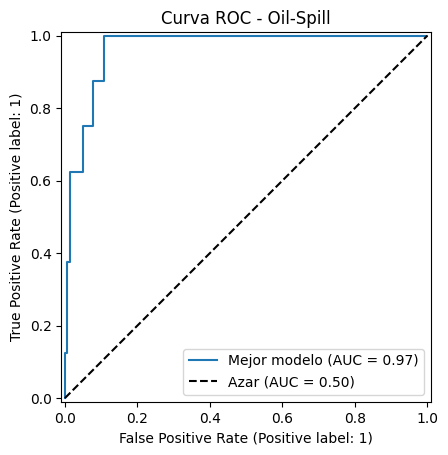

AUC ROC: 0.96576


In [14]:
# Respuesta Ejercicio-6c:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**

prob_val = mejor_modelo.predict_proba(Xval)[:, 1]

RocCurveDisplay.from_estimator(
    mejor_modelo,
    Xval,
    yval,
    name="Mejor modelo"
)

plt.plot(
    [0, 1], [0, 1], 'k--',
    label="Azar (AUC = 0.50)"
)
plt.title("Curva ROC - Oil-Spill")
plt.legend()
plt.show()

print(f"AUC ROC: {roc_auc_score(yval, prob_val):.5f}")



# **+++++++++++ Termina sección para agregar código ++++++++++++++**

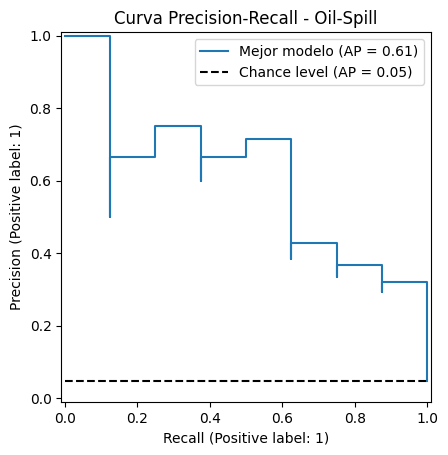

Área bajo la curva PR (Average Precision): 0.61433


In [15]:
# Respuesta Ejercicio 6d:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++**

PrecisionRecallDisplay.from_estimator(
    mejor_modelo,
    Xval,
    yval,
    name="Mejor modelo",
    plot_chance_level=True
)

plt.title("Curva Precision-Recall - Oil-Spill")
plt.legend()
plt.show()

print(f"Área bajo la curva PR (Average Precision): {average_precision_score(yval, prob_val):.5f}")


# **+++++++++++ Termina sección para agregar código ++++++++++++++**

Respuesta Ejercicio-6e:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 6e) La curva ROC muestra que el modelo tiene una buena capacidad para distinguir los registros con derrame de los que no lo tienen. Sin embargo, debido al fuerte desbalanceo de las clases, la curva ROC no refleja por sí sola cuántas de las alarmas generadas serán falsas.

La curva PR permite analizar con mayor claridad la relación entre las falsas alarmas (FP) y los derrames detectados (VP). El área bajo esta curva (0.61) es superior a su referencia aleatoria (0.05), lo que sugiere que el modelo identifica patrones útiles de la clase minoritaria.

En conclusión, el modelo es prometedor, pero todavía genera falsas alarmas. Antes de desplegarlo, debemos ajustar el umbral de decisión de acuerdo con los costos reales de los errores y mantener la supervisión humana.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [16]:
# Mostremos finalmente el siguiente resumen con varias métricas:

print(classification_report_imbalanced(np.ravel(yval), yval_hat,
                                       target_names=['class 0:non-spill', 'class 1:oil-spill']))



                         pre       rec       spe        f1       geo       iba       sup

class 0:non-spill       1.00      0.79      1.00      0.88      0.89      0.77       157
class 1:oil-spill       0.20      1.00      0.79      0.33      0.89      0.81         8

      avg / total       0.96      0.80      0.99      0.86      0.89      0.77       165



# **Ejercicio-7**

En los ejercicios previos ya lograste entrenar un buen modelo utilizando la métrica G-mean. Sin embargo, sabemos que en la industria un modelo no se despliega solamente porque tiene buenas métricas estadísticas, se despliega para resolver un problema de negocio. Introduzcamos a continuación información en esta dirección.

En los ejercicios anteriores el umbral de decisión por defecto del modelo logístico (independientemente de si usamos L1, L2 o ElasticNet) fue 0.5. Con este valor de decisión de 0.5 y del reporte de métricas de la celda anterior, observamos que aproximadamente el modelo detecta el 100% de los derrames (Recall ≈ 1.0), pero a costa de generar muchas falsas alarmas (Precisión ≈ 0.20).

Sabemos que el umbral de decisión predeterminado de 0.5 de los modelos logísticos es una convención arbitraria. Como ingenieros de IA, deberán ajustar ahora este umbral tomando en cuenta el costo de de cada nuno de los errores.

* **El Escenario de Negocio es el siguiente: Imagina que estás desplegando este modelo para la Guardia Costera y la Agencia de Protección Ambiental y te proporcionan la siguiente información:**

   * **Costo de un Falso Negativo (FN):** Cuando el modelo predice erróneamente que el "océano está limpio" y que no hay derrame de combustible, el costo es de $1,000,000 USD. El costo considera multas, limpieza de emergencia, daño ecológico, técnicos especialistas, disminución de tu reputación, etc.

   * **Costo de un Falso Positivo (FP):** Cuando el modelo predice erróneamente que "sí hay derrame", el costo es de $15,000 USD. Puede ser la detección de los llamados casos "look-alike", como las manchas de algas, entre otros. El costo considera el uso y combustible de un helicóptero para inspeccionar, horas hombre, entre otros.

   * El costo de error de los **casos Verdaderos (TP y TN)** es de $0 USD.

* **7a) Con base a esta información y tu mejor modelo encontrado previamente, utiliza un modelo de lenguaje de gran tamaño, LLM, para que te ayude a escribir una función en Python que calcule el "Costo Total Esperado" del problema, iterando a través de diferentes umbrales de probabilidad (desde 0.1 hasta 0.9). Utiliza solamente el conjunto de validación.**

* **7b) Incluye además una gráfica del Costo Total Esperado (eje Y)contre el valor de umbral (eje X). Despliega e indica visualmente dicho valor del umbral óptimo obtenido y su valor del costo total asociado.**

* **7c) A modo de comparación, muestra la matriz de confusión (en valores brutos) y el valor de la métrica G-mean para el caso del umbral de decisión predeterminado 0.5 y el del mejor umbral obtenido en los incisos anteriores.**

* **7d) ¿Cómo cambia la estrategia de despliegue respecto al umbral original predeterminado de 0.5? En particular, ¿consideras que vale la pena cambiarlo?**

* **7e) Indica el LLM utilizado e incluye el prompt o prompts que usaste en los incisos 7a y 7b anteriores.**





Umbral óptimo: 0.6300
Costo mínimo: 255000


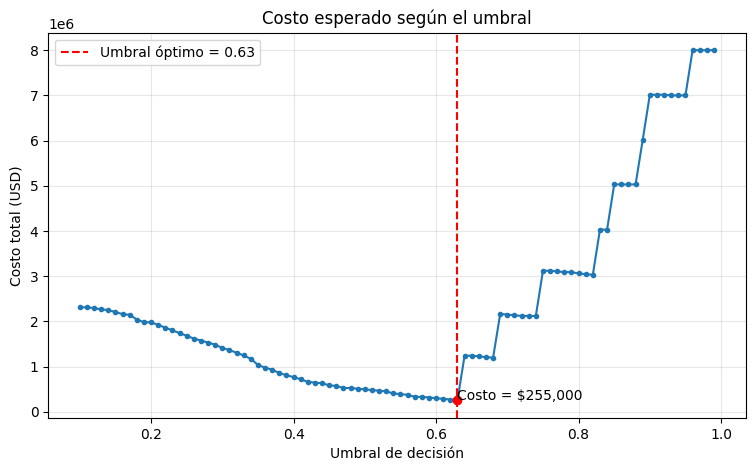


Umbral: 0.50
Matriz de confusión:
[[124  33]
 [  0   8]]
G-mean: 0.8887
Costo total: 495000.00

Umbral: 0.63
Matriz de confusión:
[[140  17]
 [  0   8]]
G-mean: 0.9443
Costo total: 255000.00


In [17]:
# Respuesta Ejercicio 7:

# +++++++ Incluye a continuación todos las celdas de texto y código que consideres adecuadas.

# 7 a) Optimización del código esperado
def costo_total_esperado(
    y_real, probabilidades,
    umbrales=np.arange(0.1, 1.0, 0.01),
    costo_fp=15000,
    costo_fn=1000000
):
    costos = []

    for umbral in umbrales:
        pred = (probabilidades >= umbral).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_real, pred, labels=[0, 1]
        ).ravel()

        costo = fp * costo_fp + fn * costo_fn
        costos.append(costo)

    return np.array(umbrales), np.array(costos)

umbrales, costos = costo_total_esperado(
    np.ravel(yval), prob_val
)

i_optimo = np.argmin(costos)
umbral_optimo = umbrales[i_optimo]
costo_optimo = costos[i_optimo]

print(f"Umbral óptimo: {umbral_optimo:.4f}")
print("Costo mínimo:", costo_optimo)


# 7b) Gráfica del costo total esperado
plt.figure(figsize=(9, 5))
plt.plot(umbrales, costos, marker='.')
plt.axvline(
    umbral_optimo,
    color='red',
    linestyle='--',
    label=f'Umbral óptimo = {umbral_optimo:.2f}'
)
plt.scatter(
    umbral_optimo, costo_optimo,
    color='red', zorder=3
)
plt.annotate(
    f'Costo = ${costo_optimo:,.0f}',
    (umbral_optimo, costo_optimo)
)
plt.xlabel("Umbral de decisión")
plt.ylabel("Costo total (USD)")
plt.title("Costo esperado según el umbral")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# 7c) Comparación del umbral 0.5 y el umbral óptimo
for th in [0.5, umbral_optimo]:
    pred = (prob_val >= th).astype(int)

    print(f"\nUmbral: {th:.2f}")
    print("Matriz de confusión:")
    print(confusion_matrix(yval, pred))
    print(f"G-mean: {geometric_mean_score(yval, pred):.4f}")

    tn, fp, fn, tp = confusion_matrix(
        yval, pred, labels=[0, 1]
    ).ravel()

    print(f"Costo total: {fp * 15000 + fn * 1000000:.2f}")


7d) Sí, en esta ejecución conviene cambiar el umbral de 0.5 a aproximadamente 0.63, porque disminuye el número de falsas alarmas y el costo total sin incrementar los falsos negativos observados en validación.
Sin embargo, esta conclusión no garantiza que el mismo umbral tenga idéntico desempeño en producción. La validación contiene pocos derrames (VP), por lo que debemos probar el umbral con nuevos datos, monitorear los errores y recalibrarlo si cambian las condiciones.
Además, dado que el costo de un falso negativo es mucho mayor, no debemos elegir un umbral únicamente para reducir gastos: debemos comprobar que la tasa de derrames omitidos (tasa de falsos negativos) siga siendo aceptable.

7e) LLM utilizado: ChatGPT, de OpenAI.

Prompt para el inciso 7a:
Escribe una función en Python que reciba las etiquetas reales y las probabilidades predichas de un clasificador binario. La función debe evaluar umbrales de 0.1 a 0.9, calcular la matriz de confusión y obtener el costo total de los errores, considerando 15,000 USD por falso positivo y 1,000,000 USD por falso negativo. Utiliza únicamente el conjunto de validación y devuelve los costos para todos los umbrales.

Prompt para el inciso 7b:
Escribe código en Python para graficar el costo total esperado contra el umbral de decisión. Identifica y marca el umbral que minimiza el costo, muestra el costo mínimo en la gráfica y utiliza los resultados calculados exclusivamente con el conjunto de validación.

# **Ejercicio-8**

**Has completado el ciclo de desarrollo y análisis del modelo de detección de derrames. Considera que tenemos el problema de derramamiento de combustible anterior y todo el análisis que has realizado hasta ahora. A continuación, deberás hacer un reporte para "vender tu solución". Para ello, considera el siguiente escenario:**

* **Supongamos que eres el ingeniero líder de IA de la Guarda Costera. A tu Director de Operaciones (que no conoce de tecnicismos de IA o Estadística) le hicieron llegar un reporte generado automáticamente por una herramienta de Inteligencia de Negocio (BI, por sus siglas en inglés). La conclusión de dicho reporte dice lo siguiente:**

     * **"El modelo tiene una Exactitud (Accuracy) del 96%. ¡Es casi perfecto! Propongo despedir a los 3 analistas humanos y dejar que el modelo envíe automáticamente los helicópteros de inspección cada vez que detecte algo".**


* **Tú sabes que esta conclusión es peligrosa e incorrecta tan solo por el alto desbalanceo de clases, pero además porque ya tienes los resultados analíticos anteriores de esta actividad que te pueden ayudar a soportar mejores decisiones y refutar la conlusión del reporte de la herramienta de BI.**

* **Redacta un reporte ejecutivo de máximo 1 página (400 palabras aproximadamente) dirigido al Director de Operaciones y con las siguientes características:**
   * **El reporte no debe estar lleno te fórmulas o métricas. En dado caso, si decides mencionar explícitamente por ejemplo "G-mean" o "curva ROC", deberás primero explicarlas.**
   
   * **El reporte debe incluir una explicación de las implicaciones de cometer errores de FP o FN con el modelo ingenuo, en comparación con los resultados de tu mejor modelo. La explicación debe ser nuevamente en el contexto del problema y sin tecnicismos.**

   * **Propón un plan de despliegue concreto del modelo que justifique y ayude a mantener a los 2 analistas humanos en sus puestos de trabajo. NOTA: Puedes revisar y aporate en el concepto conocido en inglés como "Human-in-the-loop" en IA.**







Respuesta Ejercicio-8):

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

# Reporte ejecutivo: Sistema de apoyo para la detección de derrames de petróleo

**Dirigido al Director de Operaciones**

## Resumen y recomendación

Recomiendo implementar el modelo de inteligencia artificial como una herramienta de apoyo a los analistas, no como un sustituto de la supervisión humana ni como un sistema que envíe automáticamente helicópteros sin revisión.

El reporte de inteligencia de negocios destaca una exactitud del 96%, pero este indicador puede ser engañoso. En nuestros datos, aproximadamente el 95.6% de los registros corresponden a zonas sin derrame. Un sistema que siempre prediga que el océano está limpio podría alcanzar una exactitud cercana al 96% sin detectar ningún derrame real.

## Riesgos y comparación de modelos

Un falso negativo ocurre cuando el sistema no detecta un derrame existente. Esto puede retrasar la limpieza y aumentar considerablemente el daño ambiental y económico. Un falso positivo ocurre cuando el sistema identifica un derrame inexistente, lo que genera inspecciones y gastos innecesarios.

El modelo ingenuo es inadecuado porque puede ignorar todos los derrames. En cambio, el modelo ajustado con mayor atención a la clase minoritaria consiguió detectar los ocho derrames presentes en nuestro conjunto de validación, aunque generó falsas alarmas. Esto representa una mejora importante, pero no demuestra que el sistema sea infalible.

La evaluación también muestra que es posible reducir las falsas alarmas ajustando el umbral de decisión. En la validación realizada, el umbral optimizado redujo el costo estimado de los errores de 495,000 a 255,000 dólares, sin falsos negativos observados. Estos resultados deberán confirmarse con más datos antes de su implementación.

## Plan de despliegue propuesto

Propongo una implementación gradual con supervisión humana:

1. **Fase piloto:** el modelo analiza imágenes y genera alertas con una estimación de confianza, sin activar automáticamente los recursos.
2. **Revisión humana:** los dos analistas revisan las alertas, priorizan los casos de mayor riesgo y descartan posibles falsas alarmas.
3. **Inspección operativa:** la Guardia Costera decide cuándo enviar recursos, considerando la evidencia disponible y el costo potencial de ignorar un derrame.
4. **Monitoreo continuo:** se registran los aciertos, errores, costos y tiempos de respuesta para evaluar periódicamente el desempeño y actualizar el modelo.

## Conclusión

La inteligencia artificial puede acelerar la detección y ayudar a utilizar mejor los recursos, pero no debe reemplazar el criterio humano. Mantener a los analistas permite validar las alertas, gestionar situaciones ambiguas y mejorar continuamente el sistema. La recomendación es desplegar un modelo supervisado, medible y sujeto a revisión operativa.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-9**

### **Incluye tus conclusiones finales.**


### +++++++++++ Inicia sección de Conclusiones ++++++++++++++++

El desarrollo de este ejercicio permitió comprender que la evaluación de un modelo de clasificación debe considerar el contexto del problema y no solamente su exactitud. Cuando existe un fuerte desbalanceo entre las clases, un modelo puede obtener resultados aparentemente buenos sin detectar adecuadamente la clase minoritaria.

La métrica G-mean resultó útil para comparar modelos porque considera tanto la detección de derrames como la identificación correcta de zonas sin derrame. También aprendí que la validación cruzada permite comparar configuraciones de hiperparámetros y estimar la variabilidad de los resultados, mientras que las curvas ROC y PR ayudan a estudiar la capacidad de discriminación del modelo.

Finalmente, el análisis de costos demostró que el umbral de decisión influye directamente en el número de falsas alarmas, los derrames omitidos y los costos operativos. Por eso, un modelo no debe desplegarse únicamente por sus métricas estadísticas: también debe responder a los objetivos del negocio, validarse con datos adicionales y contar con supervisión humana.

**Declaración de uso de IA**

Microsoft. (2026). Copilot (basado en GPT-4) [Modelo de lenguaje grande], utilizado para corrección de ortografía y redacción, consulta de información.

OpenAI. (2026). ChatGPT (basado en GPT-4) [Modelo de lenguaje grande], utilizado para generación de código, correción de errores y generación de reporte ejecutivo.


### +++++++++++ Termina sección de conclusiones ++++++++++++++

# **<<< Fin de la Actividad de la Semana - Clases Desbalanceadas - Oil-Spill >>>**